In [1]:
import tensorflow as tf

In [2]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

In [3]:
model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(10, activation='softmax'))

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [4]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [5]:
model.fit(x_train, y_train, epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9245 - loss: 0.2602
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9666 - loss: 0.1062
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9769 - loss: 0.0724


In [6]:
model.save('pic_num_reader.keras')

In [7]:
model=tf.keras.models.load_model('pic_num_reader.keras')

In [8]:
loss, accuracy = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9738 - loss: 0.0861


In [9]:
print('Loss:', loss)
print('Accuracy:', accuracy)

Loss: 0.08614897727966309
Accuracy: 0.973800003528595


In [10]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
The number is probably a  2


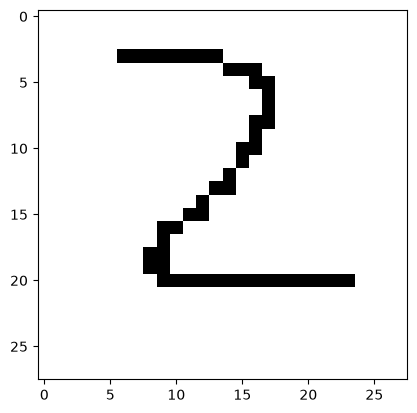

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
The number is probably a  7


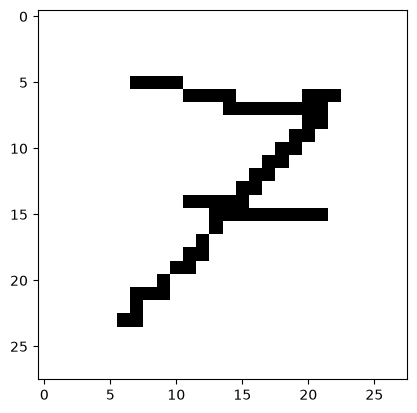

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
The number is probably a  8


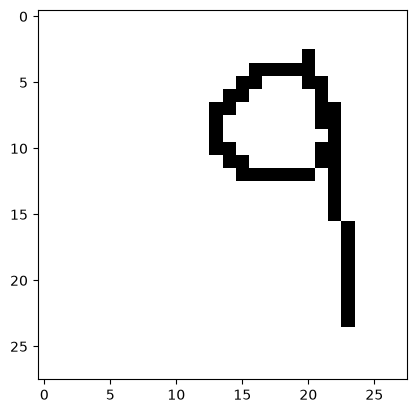

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
The number is probably a  5


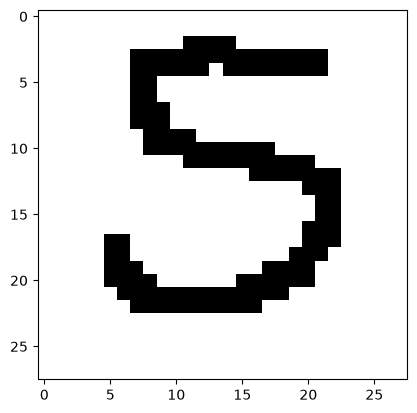

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The number is probably a  6


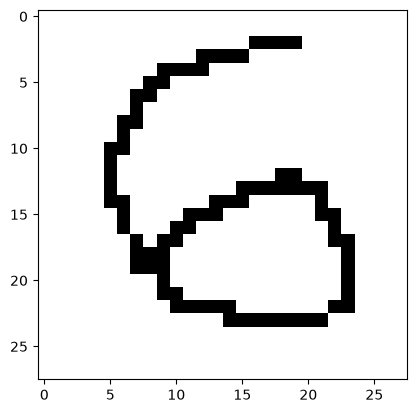

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
The number is probably a  1


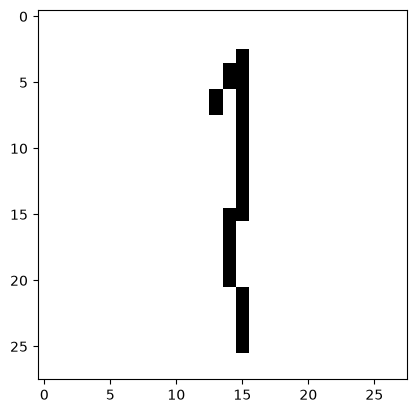

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The number is probably a  4


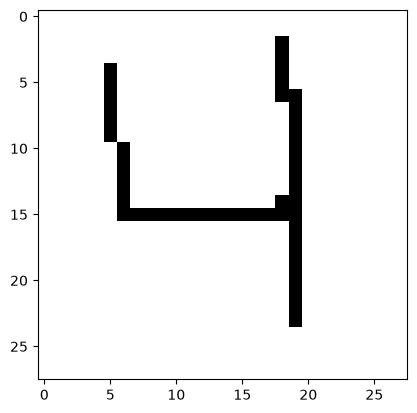

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
The number is probably a  3


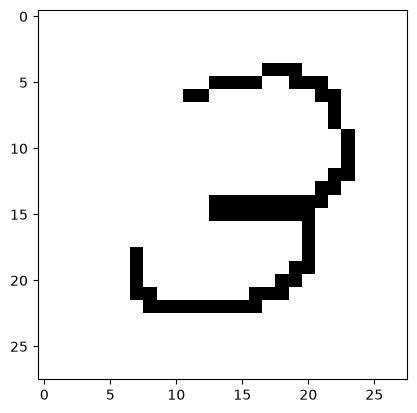

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
The number is probably a  4


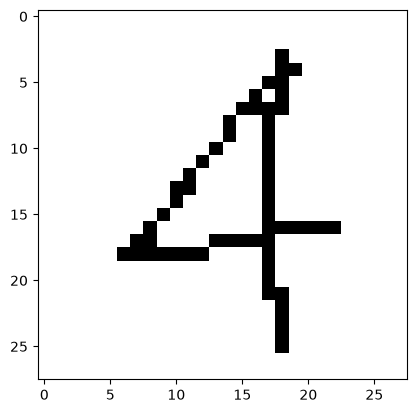

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
The number is probably a  0


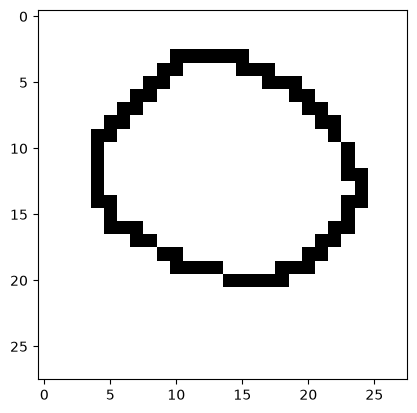

In [11]:
i=1
while os.path.exists(f'digit{i}.png'):
    img = cv2.imread(f'digit{i}.png')[:,:,0]
    img = np.invert(np.array([img]))
    p=model.predict(img)
    print("The number is probably a ", np.argmax(p))
    plt.imshow(img[0], cmap=plt.cm.binary)
    plt.show()
    i+=1